## Dataset and output at a glance

### What is the data source?

**Public Transport Authority Stops (PTA-001)** is an official point dataset published by the Western Australian Public Transport Authority through Data WA. Each row represents a recorded public-transport stop location. The layer covers bus, rail and ferry stops across Western Australia and includes stop categories such as `Standard`, `School`, `Rail`, `Ferry`, `CAT`, `Standard\CAT` and `Transwa`. The source is updated regularly, so this notebook saves a dated snapshot before calculating features.

### Which API is used?

This notebook uses the official **Data WA SLIP ArcGIS REST MapServer API**, specifically layer 14 of the `SLIP_Public_Services/Transport` service:

```text
https://public-services.slip.wa.gov.au/public/rest/services/
SLIP_Public_Services/Transport/MapServer/14
```

A GET request to the layer URL with `f=json` returns layer metadata, including the available fields and maximum record count. Requests to the `/query` endpoint return the stop records. The notebook first uses `returnCountOnly=true` to obtain the official total, then downloads ordered pages with `resultOffset` and `resultRecordCount`, requests only the required fields through `outFields`, and asks the service to return point coordinates in `EPSG:4326` through `outSR=4326`. The combined page count must equal the server total before feature calculation begins. This is an ArcGIS spatial-data API; it is **not** the Transperth GTFS timetable feed.

Useful source fields include the stop identifier (`stopid`), current source status (`Active` or `Planned`), stop type (`stoptype`), stop name, locality information and geographic coordinates. These fields allow us to identify where active stops are, what type of stop is nearest to a model site, and how many active stop points are located nearby.

The source does **not** directly provide pedestrian counts, passenger boardings, walking routes, live arrivals, service reliability or verified timetable frequency. Therefore, the output describes the public-transport environment around a site; it does not measure how many people actually use public transport there.

### What does this notebook extract?

Only the following **three columns are candidate model features**:

| Candidate feature | Plain meaning | How to interpret it |
|---|---|---|
| `pta_nearest_active_stop_distance_m` | Straight-line distance in metres from the model site to the nearest unique stop whose source status is `Active`. | A smaller value means an active stop is physically closer. It is not walking-route distance. |
| `pta_nearest_active_stop_type` | The original PTA `stoptype` of the nearest active stop, such as `Standard`, `School` or `Transwa`. | Describes the type of the nearest transport context. The categories have no numeric order and may be too sparse for the final model. |
| `pta_active_stops_within_500m` | Number of unique active stop points within a 500 m straight-line radius of the model site. | A larger value means more recorded stop points nearby. It does not mean more departures or higher service frequency. |

The output also retains three supporting fields that are **not ordinary predictors**:

| Supporting field | Purpose |
|---|---|
| `site_id` | The only key used to join this table back to `Model_Data`. |
| `pta_data_status` | QA status showing whether the site was matched, had no active stop within 500 m, or had an invalid coordinate. |
| `pta_nearest_stop_id` | PTA identifier of the nearest active stop, retained only for checking and future linkage. It must not be treated as a number in the model. |

In short, the notebook tests two simple ideas: **proximity to the nearest active stop** and **local supply of active stop points**. Whether these candidates improve pedestrian-flow prediction must still be tested with grouped/spatial cross-validation; extraction does not guarantee model usefulness.

In [8]:
from datetime import date
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from openpyxl import load_workbook
from openpyxl.styles import Alignment, Font, PatternFill
from openpyxl.utils import get_column_letter
from pyproj import Transformer
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry


def find_project_root() -> Path:
    """Find the project repository from common notebook launch locations."""
    current = Path.cwd().resolve()
    for path in [current, *current.parents]:
        if (path / "requirements.txt").is_file() and (path / "data").is_dir():
            return path
    raise FileNotFoundError(
        f"Project root not found from {current}. Expected a repository root containing data/."
    )


PROJECT_ROOT = find_project_root()
MODEL_DATASET_PATH = PROJECT_ROOT / "data" / "processed" / "model_dataset.xlsx"
SNAPSHOT_DATE = date.today().isoformat()
SNAPSHOT_DIR = PROJECT_ROOT / "data" / "external_raw" / "pta_stops" / SNAPSHOT_DATE
SNAPSHOT_GEOJSON_PATH = SNAPSHOT_DIR / "pta_stops.geojson"
SNAPSHOT_METADATA_PATH = SNAPSHOT_DIR / "pta_layer_metadata.json"
OUTPUT_DIR = PROJECT_ROOT / "06_outputs" / "02_feature_extraction"
FEATURE_OUTPUT_PATH = OUTPUT_DIR / "02_03_haoqi_pta_stops_features.xlsx"

LAYER_URL = (
    "https://public-services.slip.wa.gov.au/public/rest/services/"
    "SLIP_Public_Services/Transport/MapServer/14"
)
QUERY_URL = f"{LAYER_URL}/query"
BUFFER_RADIUS_M = 500.0
REQUEST_TIMEOUT_SECONDS = 120

if not MODEL_DATASET_PATH.is_file():
    raise FileNotFoundError(f"Required project file not found: {MODEL_DATASET_PATH}")

SNAPSHOT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root :", PROJECT_ROOT)
print("Model input  :", MODEL_DATASET_PATH.relative_to(PROJECT_ROOT))
print("Snapshot date:", SNAPSHOT_DATE)
print("Feature file :", FEATURE_OUTPUT_PATH.relative_to(PROJECT_ROOT))

Project root : /workspace
Model input  : data/processed/model_dataset.xlsx
Snapshot date: 2026-08-25
Feature file : 06_outputs/02_feature_extraction/02_03_haoqi_pta_stops_features.xlsx


## 1. Read and validate the authoritative model sites

The current `Model_Data` worksheet is the authoritative 49-site foundation. Only the four fields needed for spatial extraction are selected. `site_id` is the sole final join key; `latitude` and `longitude` are WGS84 decimal degrees; `coordinate_crs` confirms the coordinate reference system. The pedestrian targets, road attributes, `qa_status`, and notes are deliberately not copied into the feature output.

Identifier completeness and uniqueness are hard requirements because duplicate keys would invalidate a team `one_to_one` merge. Coordinate problems are retained as an explicit `invalid_coordinate` status rather than causing a site to disappear. A conservative Western Australia bounding check is used only to catch obvious input errors; it is not a precise state-boundary test.

In [9]:
model_data = pd.read_excel(
    MODEL_DATASET_PATH,
    sheet_name="Model_Data",
    dtype={"site_id": "string", "coordinate_crs": "string"},
)

site_columns = ["site_id", "latitude", "longitude", "coordinate_crs"]
missing_columns = set(site_columns) - set(model_data.columns)
if missing_columns:
    raise ValueError(f"Model_Data is missing: {sorted(missing_columns)}")

sites = model_data[site_columns].copy()
sites["site_id"] = sites["site_id"].str.strip()
sites["coordinate_crs"] = sites["coordinate_crs"].str.strip().str.upper()
sites["latitude"] = pd.to_numeric(sites["latitude"], errors="coerce")
sites["longitude"] = pd.to_numeric(sites["longitude"], errors="coerce")

if sites["site_id"].isna().any() or sites["site_id"].eq("").any():
    raise ValueError("site_id contains missing or blank values.")
if sites["site_id"].duplicated().any():
    duplicates = sites.loc[sites["site_id"].duplicated(), "site_id"].tolist()
    raise ValueError(f"site_id must be unique. Duplicates: {duplicates}")

sites["valid_coordinate"] = (
    sites["latitude"].between(-36, -13)
    & sites["longitude"].between(112, 130)
    & sites["coordinate_crs"].eq("EPSG:4326")
)

print(f"Input sites: {len(sites):,}")
print(f"Unique site_id values: {sites['site_id'].nunique():,}")
print(f"Valid WGS84 WA coordinates: {sites['valid_coordinate'].sum():,}")
display(sites.head())

Input sites: 49
Unique site_id values: 49
Valid WGS84 WA coordinates: 49


,site_id,latitude,longitude,coordinate_crs,valid_coordinate
0,250303-01,-32.866282,115.705163,EPSG:4326,True
1,250303-02,-33.359642,115.678041,EPSG:4326,True
2,250303-03,-33.360624,116.154738,EPSG:4326,True
3,250303-04,-34.238746,116.149491,EPSG:4326,True
4,250303-05,-32.628918,115.874612,EPSG:4326,True


## 2. Download and inspect the official PTA-001 stop snapshot

The official ArcGIS layer currently exposes `stopid`, `stopnumber`, `status`, `stopname`, `location`, `stoptype`, `suburb`, `accessible`, `shelter`, and several abbreviated service fields. The layer metadata and every raw record are saved with the retrieval date. Because the service limit can be lower than the total record count, the code downloads ordered pages and verifies that the combined row count exactly equals the server's `returnCountOnly` result. Existing files for the same date are reused, making reruns stable within that snapshot. Before spatial calculation, exact duplicate records are removed from the in-memory analysis copy so a repeated source row cannot inflate a 500 m stop count; the dated raw snapshot remains unchanged. Any repeated `stopid` with conflicting attributes or coordinates causes a hard error rather than an assumed resolution.

The selected output fields are intentionally limited:

| Output field | Definition | Modelling role |
|---|---|---|
| `pta_nearest_active_stop_distance_m` | Planar straight-line metres from the site to the nearest record whose source `status` is exactly `Active`. | Candidate continuous proximity feature. Consider a log transform inside each training fold because distances are likely skewed. |
| `pta_nearest_active_stop_type` | Unchanged source `stoptype` of that nearest active stop. Current layer categories must be inspected rather than recoded from assumptions. | Candidate categorical context feature; rare levels may be unsuitable with only 49 sites. |
| `pta_active_stops_within_500m` | Number of unique active stop points within a 500 m straight-line point buffer after exact source-row deduplication. | Candidate local stop-supply feature. The 500 m radius is a transparent pilot parameter, not an official or client-confirmed walking catchment. |
| `pta_nearest_stop_id` | Source `stopid` for the nearest active stop. | Audit/linkage field only; never treat an identifier as a numeric predictor. |
| `pta_data_status` | `matched`, `valid_no_stop_within_500m`, or `invalid_coordinate` in a successful run. | QA field used to distinguish a genuine zero-within-500 m from missing input. It is not automatically a predictor. |

`accessible` and `shelter` are excluded because the current snapshot's values must first demonstrate variation. The abbreviated time-period service fields are excluded because field names alone are not a sufficient data dictionary. Planned stops are excluded from active accessibility. GTFS departures are excluded from this notebook: they require `stops.txt`, `routes.txt`, `trips.txt`, `stop_times.txt`, `calendar.txt`, and `calendar_dates.txt`, correct service-date exceptions, support for times beyond `24:00:00`, and a measured PTA-to-GTFS stop-ID match rate.

In [10]:
retry = Retry(
    total=4,
    connect=4,
    read=4,
    backoff_factor=1.0,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET"],
)
session = requests.Session()
session.headers.update({"User-Agent": "CITS5553-PTA-feature-notebook/1.0"})
session.mount("https://", HTTPAdapter(max_retries=retry))


def get_json(url: str, params: dict) -> dict:
    """Request JSON and surface ArcGIS error payloads clearly."""
    response = session.get(url, params=params, timeout=REQUEST_TIMEOUT_SECONDS)
    response.raise_for_status()
    payload = response.json()
    if "error" in payload:
        raise RuntimeError(f"ArcGIS service error: {payload['error']}")
    return payload


def download_snapshot() -> tuple[dict, dict]:
    """Download a complete, count-verified ArcGIS point snapshot."""
    metadata = get_json(LAYER_URL, {"f": "json"})
    count_payload = get_json(
        QUERY_URL,
        {"where": "1=1", "returnCountOnly": "true", "f": "json"},
    )
    expected_count = int(count_payload["count"])
    page_size = min(int(metadata.get("maxRecordCount", 2000)), 5000)
    arcgis_features = []

    for offset in range(0, expected_count, page_size):
        payload = get_json(
            QUERY_URL,
            {
                "where": "1=1",
                "outFields": (
                    "gid,stopid,stopnumber,status,stopname,location,stoptype,"
                    "suburb,accessible,shelter"
                ),
                "returnGeometry": "true",
                "outSR": 4326,
                "orderByFields": "gid ASC",
                "resultOffset": offset,
                "resultRecordCount": page_size,
                "f": "json",
            },
        )
        page = payload.get("features", [])
        if not page:
            raise RuntimeError(f"Empty page returned at offset {offset}.")
        arcgis_features.extend(page)

    if len(arcgis_features) != expected_count:
        raise RuntimeError(
            f"Snapshot count mismatch: expected {expected_count}, got {len(arcgis_features)}."
        )

    geojson_features = []
    for feature in arcgis_features:
        geometry = feature.get("geometry")
        point_geometry = None
        if geometry and geometry.get("x") is not None and geometry.get("y") is not None:
            point_geometry = {
                "type": "Point",
                "coordinates": [geometry["x"], geometry["y"]],
            }
        geojson_features.append(
            {
                "type": "Feature",
                "properties": feature.get("attributes", {}),
                "geometry": point_geometry,
            }
        )

    feature_collection = {
        "type": "FeatureCollection",
        "name": metadata.get("name", "PTA-001"),
        "crs": {"type": "name", "properties": {"name": "EPSG:4326"}},
        "features": geojson_features,
    }
    return metadata, feature_collection


if SNAPSHOT_GEOJSON_PATH.is_file() and SNAPSHOT_METADATA_PATH.is_file():
    metadata = json.loads(SNAPSHOT_METADATA_PATH.read_text(encoding="utf-8"))
    feature_collection = json.loads(SNAPSHOT_GEOJSON_PATH.read_text(encoding="utf-8"))
    snapshot_source = "cached"
else:
    metadata, feature_collection = download_snapshot()
    SNAPSHOT_METADATA_PATH.write_text(
        json.dumps(metadata, indent=2), encoding="utf-8"
    )
    SNAPSHOT_GEOJSON_PATH.write_text(
        json.dumps(feature_collection, separators=(",", ":")), encoding="utf-8"
    )
    snapshot_source = "downloaded"

stop_rows = []
for feature in feature_collection["features"]:
    row = dict(feature.get("properties", {}))
    geometry = feature.get("geometry")
    coordinates = geometry.get("coordinates") if geometry else [None, None]
    row["longitude"] = coordinates[0]
    row["latitude"] = coordinates[1]
    stop_rows.append(row)

pta_stops = pd.DataFrame(stop_rows)
pta_stops["longitude"] = pd.to_numeric(pta_stops["longitude"], errors="coerce")
pta_stops["latitude"] = pd.to_numeric(pta_stops["latitude"], errors="coerce")
pta_stops["status"] = pta_stops["status"].astype("string").str.strip()
pta_stops["stoptype"] = pta_stops["stoptype"].astype("string").str.strip()

source_record_columns = [
    "gid",
    "stopid",
    "stopnumber",
    "status",
    "stopname",
    "location",
    "stoptype",
    "suburb",
    "accessible",
    "shelter",
    "longitude",
    "latitude",
]
exact_duplicate_count = int(pta_stops.duplicated(source_record_columns).sum())
pta_stops_for_analysis = pta_stops.drop_duplicates(source_record_columns).copy()
conflicting_stop_ids = pta_stops_for_analysis.loc[
    pta_stops_for_analysis["stopid"].duplicated(keep=False), "stopid"
].dropna().unique()
if len(conflicting_stop_ids):
    raise ValueError(
        f"Repeated stopid values have conflicting source rows: {conflicting_stop_ids.tolist()}"
    )

status_counts = pta_stops["status"].value_counts(dropna=False)
active_stops = pta_stops_for_analysis.loc[
    pta_stops_for_analysis["status"].eq("Active")
    & pta_stops_for_analysis["longitude"].notna()
    & pta_stops_for_analysis["latitude"].notna()
].copy()

if active_stops.empty:
    raise ValueError("The snapshot contains no geocoded Active stops.")

print(f"Snapshot source: {snapshot_source}")
print(f"Layer name: {metadata.get('name')}")
print(f"Maximum server page size: {metadata.get('maxRecordCount')}")
print(f"Snapshot records: {len(pta_stops):,}")
print(f"Exact duplicate source rows excluded from analysis: {exact_duplicate_count:,}")
print(f"Unique geocoded active stops used: {len(active_stops):,}")
display(status_counts.rename("records").to_frame())
display(
    active_stops["stoptype"]
    .value_counts(dropna=False)
    .rename("active_stops")
    .to_frame()
)
display(
    active_stops[["accessible", "shelter"]]
    .value_counts(dropna=False)
    .rename("active_stops")
    .to_frame()
)

Snapshot source: cached
Layer name: Public Transport Authority Stops (PTA-001)
Maximum server page size: 10000
Snapshot records: 16,813
Exact duplicate source rows excluded from analysis: 7
Unique geocoded active stops used: 16,795


,records
status,
Active,16802
Planned,11


,active_stops
stoptype,
Standard,13829
School,2264
Transwa,325
Rail,188
Standard\CAT,119
CAT,68
Ferry,2


,,active_stops
accessible,shelter,
Y,Y,16795


## 3. Calculate site-level proximity and stop-supply features

Distances and the 500 m threshold must not be calculated in longitude/latitude degrees. Each valid site is assigned the WGS84 UTM south zone implied by its longitude; all active stops are projected into that same local metre-based CRS before Euclidean distances are calculated. This is accurate enough for the intended local proximity calculation across Western Australia's several UTM zones and avoids treating degrees as metres.

A site with no active stop within 500 m is still a valid, successfully processed observation. It receives `pta_active_stops_within_500m = 0`, a real nearest-stop distance, and `pta_data_status = valid_no_stop_within_500m`. Invalid input coordinates retain a row but receive missing feature values. The code does not impose a maximum nearest distance because long distances may be genuine for regional sites.

In [11]:
def utm_epsg(longitude: float, latitude: float) -> int:
    """Return the WGS84 UTM EPSG code for one coordinate."""
    zone = int((longitude + 180) // 6) + 1
    return (32600 if latitude >= 0 else 32700) + zone


valid_sites = sites.loc[sites["valid_coordinate"]].copy()
valid_sites["utm_epsg"] = [
    utm_epsg(row.longitude, row.latitude) for row in valid_sites.itertuples()
]

projected_stops_by_crs = {}
for epsg in sorted(valid_sites["utm_epsg"].unique()):
    transformer = Transformer.from_crs(4326, int(epsg), always_xy=True)
    stop_x, stop_y = transformer.transform(
        active_stops["longitude"].to_numpy(),
        active_stops["latitude"].to_numpy(),
    )
    projected_stops_by_crs[int(epsg)] = (
        transformer,
        np.asarray(stop_x),
        np.asarray(stop_y),
    )

feature_rows = []
for site in sites.itertuples():
    if not site.valid_coordinate:
        feature_rows.append(
            {
                "site_id": site.site_id,
                "pta_data_status": "invalid_coordinate",
                "pta_nearest_active_stop_distance_m": np.nan,
                "pta_nearest_active_stop_type": pd.NA,
                "pta_active_stops_within_500m": pd.NA,
                "pta_nearest_stop_id": pd.NA,
            }
        )
        continue

    epsg = utm_epsg(site.longitude, site.latitude)
    transformer, stop_x, stop_y = projected_stops_by_crs[epsg]
    site_x, site_y = transformer.transform(site.longitude, site.latitude)
    distances = np.hypot(stop_x - site_x, stop_y - site_y)
    nearest_position = int(np.argmin(distances))
    nearest_stop = active_stops.iloc[nearest_position]
    within_count = int(np.count_nonzero(distances <= BUFFER_RADIUS_M))

    feature_rows.append(
        {
            "site_id": site.site_id,
            "pta_data_status": (
                "matched" if within_count > 0 else "valid_no_stop_within_500m"
            ),
            "pta_nearest_active_stop_distance_m": round(
                float(distances[nearest_position]), 1
            ),
            "pta_nearest_active_stop_type": nearest_stop["stoptype"],
            "pta_active_stops_within_500m": within_count,
            "pta_nearest_stop_id": str(nearest_stop["stopid"]),
        }
    )

features = pd.DataFrame(feature_rows)
features["site_id"] = features["site_id"].astype("string")
features["pta_data_status"] = features["pta_data_status"].astype("string")
features["pta_nearest_active_stop_type"] = features["pta_nearest_active_stop_type"].astype("string")
features["pta_active_stops_within_500m"] = pd.array(
    features["pta_active_stops_within_500m"], dtype="Int64"
)
features["pta_nearest_stop_id"] = features["pta_nearest_stop_id"].astype("string")

display(features.head(10))

,site_id,pta_data_status,pta_nearest_active_stop_distance_m,pta_nearest_active_stop_type,pta_active_stops_within_500m,pta_nearest_stop_id
0,250303-01,valid_no_stop_within_500m,9163.3,Transwa,0,28638
1,250303-02,valid_no_stop_within_500m,564.3,Transwa,0,45001
2,250303-03,matched,265.0,School,4,38037
3,250303-04,matched,93.5,School,11,36961
4,250303-05,matched,182.2,Standard,13,45419
5,250303-06,valid_no_stop_within_500m,788.8,Transwa,0,45298
6,250303-07,matched,71.3,Transwa,1,28678
7,250303-08,matched,231.3,Transwa,2,28782
8,250303-09,matched,210.6,Transwa,1,45259
9,250303-10,matched,315.7,School,4,43205


## 4. Quality checks and project-specific diagnostics

The source is checked for total records, Active/Planned counts, stop-type distribution, and variation in the two facility fields that were rejected. The derived table is checked for one row per input `site_id`, identical key coverage, allowed status values, non-negative distances and counts, and a logically consistent relation between zero stops and status.

The diagnostics deliberately show the zero-within-500 m share, distance distribution, nearest-stop types, and the shortest and longest matches. Long regional distances are not automatically removed. They should later be interpreted alongside remoteness/UCL features and, where necessary, manually checked on the official map. The histogram uses a logarithmic distance axis only for visual readability; the saved feature remains the auditable raw metre value.

PTA feature status:


,sites
pta_data_status,
matched,34
valid_no_stop_within_500m,15


Nearest active stop type:


,sites
pta_nearest_active_stop_type,
Transwa,28
Standard,11
School,10


,pta_nearest_active_stop_distance_m,pta_active_stops_within_500m
count,49.000000,49.0
mean,12473.412245,3.44898
std,55312.159921,4.532573
min,8.600000,0.0
25%,114.900000,0.0
50%,231.300000,1.0
75%,788.800000,5.0
90%,3338.100000,11.0
max,352550.000000,17.0


Shortest-distance checks:


,site_id,latitude,longitude,pta_nearest_active_stop_distance_m,pta_nearest_active_stop_type,pta_nearest_stop_id
11,250303-12,-34.314900,115.159261,8.6,Transwa,28743
43,260335-47,-33.309062,117.344776,9.0,Transwa,28628
25,260335-29,-30.761932,121.456695,12.6,School,29173
15,250303-16,-32.628933,115.872394,30.3,Standard,45419
29,260335-33,-34.993578,117.857386,32.0,Standard,43514


Longest-distance checks:


,site_id,latitude,longitude,pta_nearest_active_stop_distance_m,pta_nearest_active_stop_type,pta_nearest_stop_id
20,250341-04,-18.196519,125.565875,352550.0,Standard,47622
19,250341-03,-17.305548,123.633717,162908.2,School,43031
46,260335-50,-30.275920,116.663871,58253.3,Transwa,29004
24,260335-28,-30.954671,121.162305,12496.5,Transwa,29305
0,250303-01,-32.866282,115.705163,9163.3,Transwa,28638


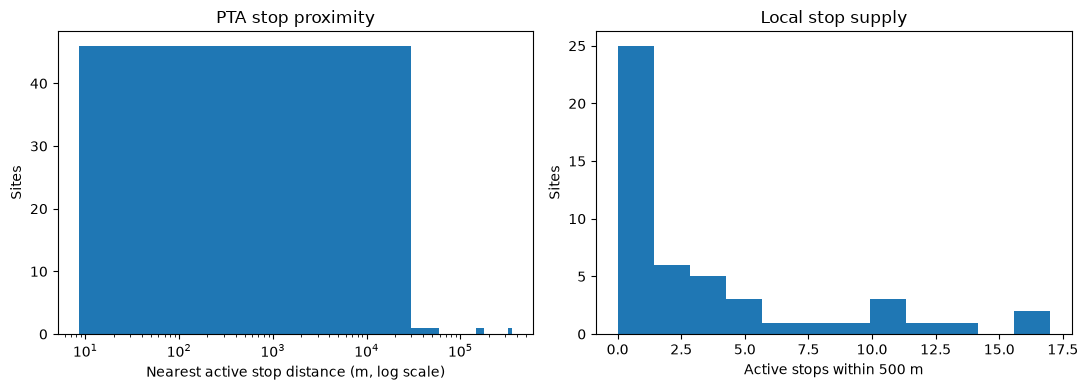

In [12]:
if len(features) != len(sites):
    raise ValueError("Feature row count does not match the model-site row count.")
if features["site_id"].duplicated().any():
    raise ValueError("Feature output contains duplicate site_id values.")
if set(features["site_id"]) != set(sites["site_id"]):
    raise ValueError("Feature output site_id coverage differs from Model_Data.")

allowed_statuses = {
    "matched",
    "valid_no_stop_within_500m",
    "invalid_coordinate",
}
unexpected_statuses = set(features["pta_data_status"].dropna()) - allowed_statuses
if unexpected_statuses:
    raise ValueError(f"Unexpected PTA statuses: {unexpected_statuses}")

valid_output = features["pta_data_status"].ne("invalid_coordinate")
if features.loc[valid_output, "pta_nearest_active_stop_distance_m"].isna().any():
    raise ValueError("Valid sites must have a nearest-stop distance.")
if (features.loc[valid_output, "pta_nearest_active_stop_distance_m"] < 0).any():
    raise ValueError("Nearest-stop distance cannot be negative.")
if (features.loc[valid_output, "pta_active_stops_within_500m"] < 0).any():
    raise ValueError("Stop count cannot be negative.")

# Compare row values after normalising nullable booleans to plain bool.
# Series.equals() is intentionally avoided because it also checks dtype metadata.
zero_count = (
    features["pta_active_stops_within_500m"]
    .eq(0)
    .fillna(False)
    .astype(bool)
)
zero_status = (
    features["pta_data_status"]
    .eq("valid_no_stop_within_500m")
    .fillna(False)
    .astype(bool)
)
inconsistent_zero_status = zero_count.ne(zero_status)
if inconsistent_zero_status.any():
    inconsistent_rows = features.loc[
        inconsistent_zero_status,
        ["site_id", "pta_data_status", "pta_active_stops_within_500m"],
    ]
    display(inconsistent_rows)
    raise ValueError(
        "Zero stop counts and valid-no-stop statuses are inconsistent. "
        "Review the displayed rows."
    )

diagnostic = sites[["site_id", "latitude", "longitude"]].merge(
    features, on="site_id", how="left", validate="one_to_one"
)

print("PTA feature status:")
display(features["pta_data_status"].value_counts(dropna=False).to_frame("sites"))
print("Nearest active stop type:")
display(
    features["pta_nearest_active_stop_type"]
    .value_counts(dropna=False)
    .to_frame("sites")
)

valid_diagnostic = diagnostic.loc[valid_output.to_numpy()].copy()
summary = valid_diagnostic[
    ["pta_nearest_active_stop_distance_m", "pta_active_stops_within_500m"]
].describe(percentiles=[0.25, 0.5, 0.75, 0.9])
display(summary)

audit_columns = [
    "site_id",
    "latitude",
    "longitude",
    "pta_nearest_active_stop_distance_m",
    "pta_nearest_active_stop_type",
    "pta_nearest_stop_id",
]
print("Shortest-distance checks:")
display(valid_diagnostic.nsmallest(5, "pta_nearest_active_stop_distance_m")[audit_columns])
print("Longest-distance checks:")
display(valid_diagnostic.nlargest(5, "pta_nearest_active_stop_distance_m")[audit_columns])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(valid_diagnostic["pta_nearest_active_stop_distance_m"], bins=12)
axes[0].set_xscale("log")
axes[0].set_xlabel("Nearest active stop distance (m, log scale)")
axes[0].set_ylabel("Sites")
axes[0].set_title("PTA stop proximity")
axes[1].hist(valid_diagnostic["pta_active_stops_within_500m"], bins=12)
axes[1].set_xlabel("Active stops within 500 m")
axes[1].set_ylabel("Sites")
axes[1].set_title("Local stop supply")
plt.tight_layout()
plt.show()

## 5. Save the independent feature table and demonstrate the team merge

The output workbook contains one worksheet, `PTA_Stop_Features`, and exactly six columns: `site_id`, one QA status, three candidate model features, and one audit identifier. It is not a copy of `model_dataset.xlsx`. Coordinates, targets, road fields, and model QA remain in the foundation table.

The round-trip check reopens the saved workbook and verifies row count, column order, key coverage, and one-to-one compatibility. The final demonstration merges back to `Model_Data` and only then applies `qa_status == "ready"`. In real model development, `pta_nearest_stop_id` should be excluded from `X`, and `pta_data_status` should be used for QA/missingness policy rather than automatically encoded as a predictor.

In [13]:
feature_columns = [
    "site_id",
    "pta_data_status",
    "pta_nearest_active_stop_distance_m",
    "pta_nearest_active_stop_type",
    "pta_active_stops_within_500m",
    "pta_nearest_stop_id",
]
features = features[feature_columns].copy()
features.to_excel(
    FEATURE_OUTPUT_PATH, sheet_name="PTA_Stop_Features", index=False
)

# Apply minimal review-friendly formatting without adding extra worksheets.
workbook = load_workbook(FEATURE_OUTPUT_PATH)
worksheet = workbook["PTA_Stop_Features"]
worksheet.freeze_panes = "A2"
worksheet.auto_filter.ref = worksheet.dimensions
header_fill = PatternFill("solid", fgColor="1F4E78")
for cell in worksheet[1]:
    cell.fill = header_fill
    cell.font = Font(color="FFFFFF", bold=True)
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
worksheet.row_dimensions[1].height = 32
column_widths = [14, 31, 41, 36, 34, 22]
for column_number, width in enumerate(column_widths, start=1):
    worksheet.column_dimensions[get_column_letter(column_number)].width = width
for row_number in range(2, worksheet.max_row + 1):
    worksheet.cell(row_number, 3).number_format = "0.0"
    worksheet.cell(row_number, 5).number_format = "0"
    worksheet.cell(row_number, 6).number_format = "@"
workbook.save(FEATURE_OUTPUT_PATH)

saved_features = pd.read_excel(
    FEATURE_OUTPUT_PATH,
    sheet_name="PTA_Stop_Features",
    dtype={"site_id": "string", "pta_nearest_stop_id": "string"},
)
if list(saved_features.columns) != feature_columns:
    raise ValueError("Saved feature columns differ from the approved schema.")
if len(saved_features) != len(sites) or saved_features["site_id"].duplicated().any():
    raise ValueError("Saved workbook is not one row per input site_id.")
if set(saved_features["site_id"]) != set(sites["site_id"]):
    raise ValueError("Saved workbook site_id coverage differs from Model_Data.")

modeling_df = model_data.merge(
    saved_features, on="site_id", how="left", validate="one_to_one"
)
training_df = modeling_df.loc[modeling_df["qa_status"].eq("ready")].copy()

print(f"Saved feature rows: {len(saved_features):,}")
print(f"Merged modelling rows: {len(modeling_df):,}")
print(f"Training rows after qa_status filter: {len(training_df):,}")
print("Output:", FEATURE_OUTPUT_PATH.relative_to(PROJECT_ROOT))
display(saved_features.head())

Saved feature rows: 49
Merged modelling rows: 49
Training rows after qa_status filter: 49
Output: 06_outputs/02_feature_extraction/02_03_haoqi_pta_stops_features.xlsx


,site_id,pta_data_status,pta_nearest_active_stop_distance_m,pta_nearest_active_stop_type,pta_active_stops_within_500m,pta_nearest_stop_id
0,250303-01,valid_no_stop_within_500m,9163.3,Transwa,0,28638
1,250303-02,valid_no_stop_within_500m,564.3,Transwa,0,45001
2,250303-03,matched,265.0,School,4,38037
3,250303-04,matched,93.5,School,11,36961
4,250303-05,matched,182.2,Standard,13,45419
